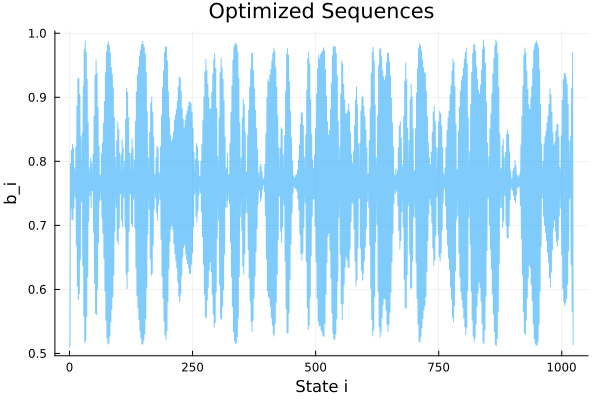

In [3]:
using DelimitedFiles
using Plots

# Update filename to match what was generated
filename = "data/optimal_sequences_N1024_M250_above_half.csv"

# Load the matrix (M rows, N-1 columns)
all_realizations = readdlm(filename, ',', Float64)
p = plot(legend=false, xlabel="State i", ylabel="b_i", title="Optimized Sequences")

# Example: Plot all realizations on the same figure
plot!(all_realizations[1, :], marker=:none, markersize=3, alpha=0.5)


display(p)

In [5]:
b_opt = all_realizations[1, :]

1023-element Vector{Float64}:
 0.5106782166611251
 0.7965592904541507
 0.7267228735743055
 0.8172547981774696
 0.7088873535795475
 0.8260475600625912
 0.7085893591444519
 0.8207581775612584
 0.7267182417689566
 0.789652703414961
 0.7662217816389534
 0.7436226726582537
 0.8228064955642895
 ⋮
 0.6081031035250033
 0.8890639167461467
 0.6602363790099003
 0.8317430373043694
 0.7447361963315773
 0.7420715780639602
 0.8391302491221839
 0.6389994469247913
 0.9142427574141616
 0.5652245487318359
 0.9702244382106942
 0.5135967746967159

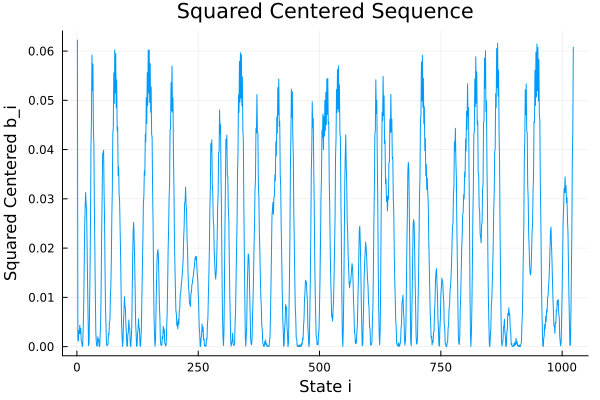

In [6]:
using Statistics

b_sq = (b_opt .- mean(b_opt)).^2

plot(b_sq, marker=:none, xlabel="State i", ylabel="Squared Centered b_i", legend=false, title="Squared Centered Sequence")

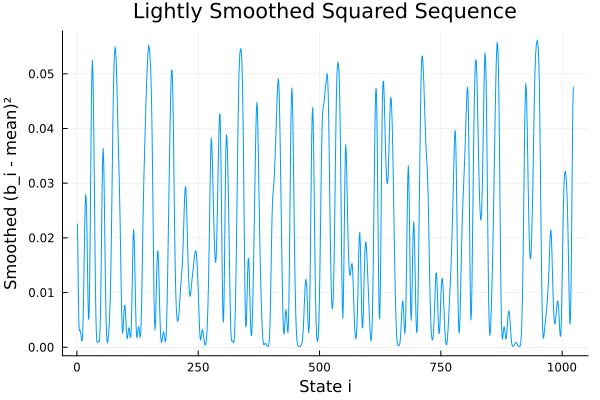

In [7]:
function smooth(iter, data)
    for _ in 1:iter
        data = [mean(data[max(1, i-1):min(end, i+1)]) for i in eachindex(data)]
    end
    return data
end

b_sm = smooth(3, b_sq)  # Apply smoothing 5 times

# Plot the smoothed squared data
plot(b_sm, marker=:none, xlabel="State i", ylabel="Smoothed (b_i - mean)²", legend=false, title="Lightly Smoothed Squared Sequence")

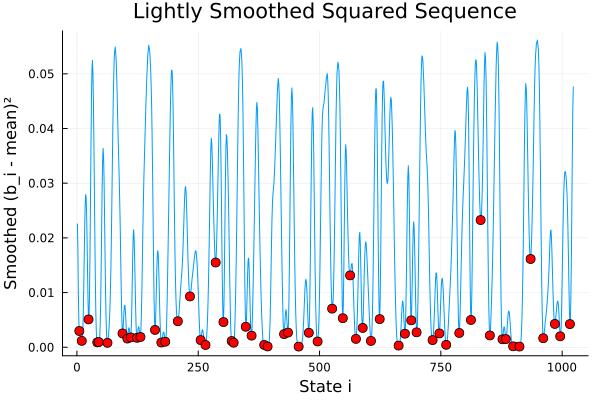

In [8]:
function detect_min(data, threshold)
    minima_indices = Int[]
    for i in 2:length(data)-1
        if data[i] < data[i-1] && data[i] < data[i+1] && data[i] < threshold*maximum(data)
            push!(minima_indices, i)
        end
    end
    return minima_indices
end

# Find the minima (make sure b_sm matches your variable name)
minima = detect_min(b_sm, 0.5)

# Plot the smoothed data line
plot(b_sm, xlabel="State i", ylabel="Smoothed (b_i - mean)²", legend=false, title="Lightly Smoothed Squared Sequence")

# Overlay the detected minima as red dots
scatter!(minima, b_sm[minima], color=:red, markersize=5)

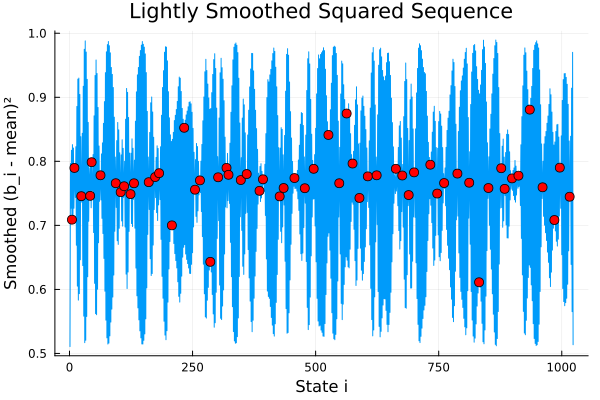

In [9]:
# Plot the smoothed data line
plot(b_opt, xlabel="State i", ylabel="Smoothed (b_i - mean)²", legend=false, title="Lightly Smoothed Squared Sequence")

# Overlay the detected minima as red dots
scatter!(minima, b_opt[minima], color=:red, markersize=5)

In [10]:
function packet_sizes(data; smooth_iters=3, threshold=0.5)
    all_sizes = Int[]
    
    for (i, realization) in enumerate(eachrow(data))
        # 1. Center the data
        centered = realization .- mean(realization)
        
        # 2. Square the data
        squared = centered.^2
        
        # 3. Smooth the data
        smoothed = smooth(smooth_iters, squared)
        
        # 4. Detect minima on the processed data
        minima = detect_min(smoothed, threshold)
        sizes = diff(minima)
        
        if isempty(sizes)
            println("Realization $i: No packets found.")
        else
            append!(all_sizes, sizes)
            println("Realization $i: Mean packet size = ", round(mean(sizes), digits=2), " (from ", length(sizes), " packets)")
        end
    end
    
    return all_sizes
end

# Extract the full list of sizes
all_packet_sizes = packet_sizes(all_realizations, smooth_iters=3, threshold=0.5)

Realization 1: Mean packet size = 17.74 (from 57 packets)
Realization 2: Mean packet size = 16.43 (from 61 packets)
Realization 3: Mean packet size = 14.64 (from 69 packets)
Realization 4: Mean packet size = 16.29 (from 62 packets)
Realization 5: Mean packet size = 15.1 (from 67 packets)
Realization 6: Mean packet size = 17.74 (from 57 packets)
Realization 7: Mean packet size = 18.8 (from 54 packets)
Realization 8: Mean packet size = 16.87 (from 60 packets)
Realization 9: Mean packet size = 16.03 (from 63 packets)
Realization 10: Mean packet size = 14.17 (from 71 packets)
Realization 11: Mean packet size = 17.5 (from 58 packets)
Realization 12: Mean packet size = 16.9 (from 60 packets)
Realization 13: Mean packet size = 18.12 (from 56 packets)
Realization 14: Mean packet size = 14.47 (from 70 packets)
Realization 15: Mean packet size = 17.17 (from 59 packets)
Realization 16: Mean packet size = 16.13 (from 62 packets)
Realization 17: Mean packet size = 17.1 (from 59 packets)
Realization

15612-element Vector{Int64}:
  5
 14
 18
  3
 18
 31
 10
  7
 13
  7
 30
 13
  8
  ⋮
 15
 13
 28
 14
 16
 18
 18
 12
 10
 17
  9
 10

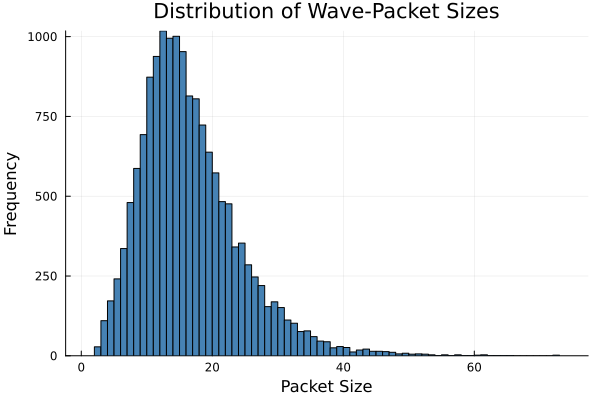

In [11]:
using Plots

# Plot the distribution of the collected packet sizes
histogram(
    all_packet_sizes,
    bins=maximum(all_packet_sizes) - minimum(all_packet_sizes) + 1,
    xlabel="Packet Size",
    ylabel="Frequency",
    title="Distribution of Wave-Packet Sizes",
    legend=false,
    grid=true,
    color=:steelblue
)

N=16: Found 107 packets. Mean=7.12, Var=2.9
N=32: Found 515 packets. Mean=9.57, Var=12.65
N=64: Found 1194 packets. Mean=10.78, Var=18.64
N=128: Found 2563 packets. Mean=11.24, Var=20.06
N=200: Found 4046 packets. Mean=11.62, Var=21.71
N=256: Found 4495 packets. Mean=13.54, Var=33.3
N=512: Found 8059 packets. Mean=15.47, Var=41.23
N=1024: Found 16804 packets. Mean=15.06, Var=38.08
N=2048: Found 37267 packets. Mean=13.66, Var=30.94


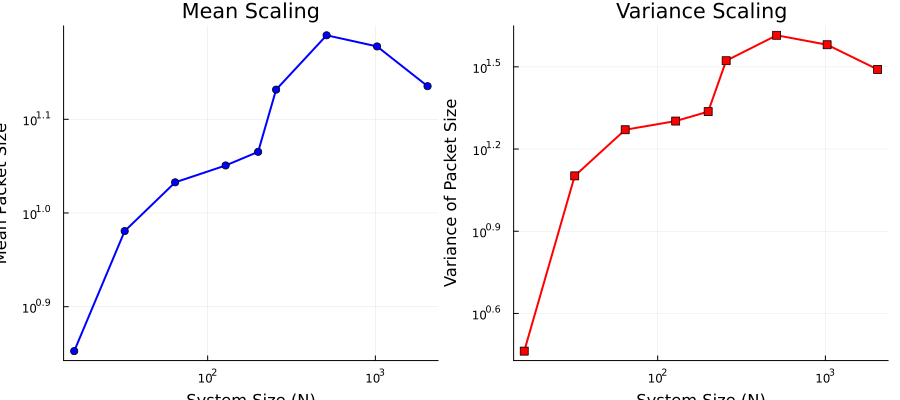

In [ ]:
using DelimitedFiles
using Statistics
using Plots

# Define N values logarithmically spaced (powers of 2 are excellent for log-log plots)
N_values = [16, 32, 64, 128, 200, 256, 512, 1024, 2048]

# Adjust these parameters to match how you will generate your data
M = 250
suffix = "above_half"
data_dir = joinpath(@__DIR__, "data")

function smooth(iter, data)
    for _ in 1:iter
        data = [mean(data[max(1, i-1):min(end, i+1)]) for i in eachindex(data)]
    end
    return data
end

function detect_min(data, threshold)
    minima_indices = Int[]
    for i in 2:length(data)-1
        if data[i] < data[i-1] && data[i] < data[i+1] && data[i] < threshold
            push!(minima_indices, i)
        end
    end
    return minima_indices
end

function extract_packet_sizes(data_matrix; smooth_iters=3, threshold=0.5)
    all_sizes = Int[]
    for realization in eachrow(data_matrix)
        centered = realization .- mean(realization)
        squared = centered.^2
        smoothed = smooth(smooth_iters, squared)
        minima = detect_min(smoothed, threshold)
        sizes = diff(minima)
        
        if !isempty(sizes)
            append!(all_sizes, sizes)
        end
    end
    return all_sizes
end

# Storage for plotting
means = Float64[]
variances = Float64[]
valid_Ns = Int[]

# 1. Load data and calculate statistics
for N in N_values
    filename = joinpath(data_dir, "optimal_sequences_N$(N)_M$(M)_$(suffix).csv")
    
    if isfile(filename)
        data_matrix = readdlm(filename, ',', Float64)
        sizes = extract_packet_sizes(data_matrix, smooth_iters=3, threshold=0.5)
        
        if !isempty(sizes)
            push!(means, mean(sizes))
            push!(variances, var(sizes))
            push!(valid_Ns, N)
            println("N=$N: Found $(length(sizes)) packets. Mean=$(round(mean(sizes), digits=2)), Var=$(round(var(sizes), digits=2))")
        else
            println("N=$N: File found but no packets detected.")
        end
    else
        println("Missing file for N=$N, skipping... ($filename)")
    end
end

# 2. Plotting on a log-log scale
mean_plot = plot(
    valid_Ns, means./N_values[1:length(valid_Ns)],  # Normalize by the first N value
    xscale=:log10, yscale=:log10,
    marker=:circle, color=:blue, linewidth=2,
    xlabel="System Size (N)", ylabel="Mean Packet Size",
    title="Mean Scaling", legend=false, grid=true
)

variance_plot = plot(
    valid_Ns, variances./N_values[1:length(valid_Ns)],  # Normalize by the first N value
    xscale=:log10, yscale=:log10,
    marker=:square, color=:red, linewidth=2,
    xlabel="System Size (N)", ylabel="Variance of Packet Size",
    title="Variance Scaling", legend=false, grid=true
)

# Combine both plots side-by-side
combined_plot = plot(mean_plot, variance_plot, layout=(1, 2), size=(900, 400))
display(combined_plot)